# Running IGNR (Implicit Graphon Neural Representation) on a Single Example

This notebook clones and runs the **original** IGNR code directly (no reimplementation) for one example graphon, then plots the true graphon against the estimated one.

Reference: Xia, Mishne & Wang, *"Implicit Graphon Neural Representation"*, AISTATS 2023.
Code: [https://github.com/Mishne-Lab/IGNR](https://github.com/Mishne-Lab/IGNR)

## 1. Clone the repo and install dependencies

In [ ]:
import sys

!git clone -q https://github.com/Mishne-Lab/IGNR.git
!pip install -q torch pot siren-pytorch einops networkx opencv-python python-igraph

# graphons.py (your helper module): download on Colab, read from ../src locally
if "google.colab" in sys.modules:
    BASE = "https://raw.githubusercontent.com/sevvandi/sevvandi.github.io/BRANCH/assets/notebooks/NeurIPS_2026/src"
    !wget -q {BASE}/graphons.py
else:
    sys.path.insert(0, "../src")

fatal: destination path 'IGNR' already exists and is not an empty directory.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.3/48.3 MB 3.9 MB/s  0:00:12m0:00:0100:01


(`torch_geometric` is only needed for the `cIGNR` folder / conditional model -- not required here, since we're only using the single-graphon `IGNR` folder.)

## 2. Point Python at the cloned repo and import their code

In [12]:
import sys, os, pickle
import numpy as np
import matplotlib.pyplot as plt
import sys

# `model_IGNR.py` and `helper.py` live in IGNR/IGNR, and import each other
# with bare `from model_IGNR import *` / `from helper import *`, so that
# folder needs to be on sys.path (not just the repo root).
repo_dir = os.path.join(os.getcwd(), "IGNR", "IGNR")
sys.path.insert(0, repo_dir)

from model_IGNR import *   # IGNR, IGNR_pg_wrapper, IGNR_cg_wrapper
from helper import *       # synthesize_graphon, gw_distance, mse_sort, etc.

## 3. Load their pre-synthesized graph data

In [14]:
# Same file train_IGNR.py loads: a pickle of graph collections for each
# of their 13 synthetic graphon types, each with several trials.
with open(os.path.join(repo_dir, "Data", "graphs.pkl"), "rb") as f:
    data = pickle.load(f)

print(f"{len(data)} graphon types, {len(data[0])} trials each")

13 graphon types, 10 trials each


## 4. Pick one example and get the ground-truth graphon

In [18]:
i_exp = 4     # which of the 13 synthetic graphon types
i_trial = 4   # which pre-generated trial (graph collection) for that type

graphs = data[i_exp][i_trial]

graphon0 = synthesize_graphon(r=1000, type_idx=i_exp)  # ground-truth graphon, resolution 1000
np.fill_diagonal(graphon0, 0.)  # ignore diagonal entries when computing GW error, as in train_IGNR.py

print(f"Graphon type {i_exp}, trial {i_trial}: {len(graphs)} graphs, "
      f"sizes {[g.shape[0] for g in graphs]}")

Graphon type 4, trial 4: 10 graphs, sizes [50, 77, 105, 133, 161, 188, 216, 244, 272, 300]


## 5. Train IGNR (proximal-gradient path, matching train_IGNR.py's default)

In [19]:
w0 = 30.
mlp_dim_hidden = [20, 20, 20]
n_epoch = 70

gl_mlp = IGNR_pg_wrapper(mlp_dim_hidden, w0=w0)
loss = gl_mlp.train(graphs, K='input', n_epoch=n_epoch, f_sample='fixed')

print("Final training loss:", loss[-1])

Final training loss: 0.16516031558933722


(Swap `IGNR_pg_wrapper` for `IGNR_cg_wrapper` above to use the conditional-gradient path instead -- matches `train_IGNR.py`'s `--use-pg 0` option, same call signature.)

## 6. Get the estimated graphon and plot it against the ground truth

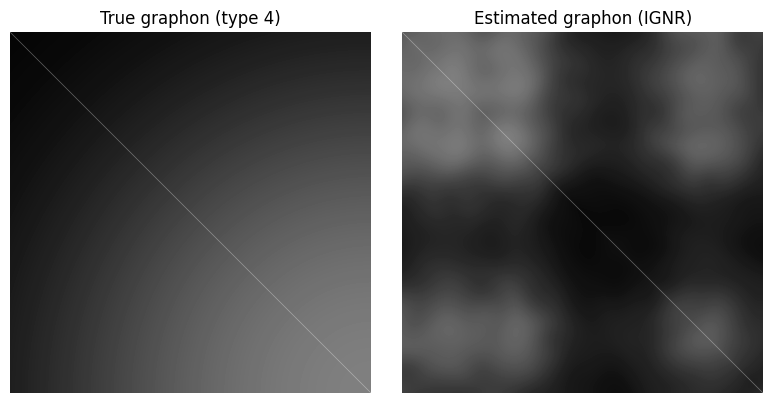

GW error vs. ground truth: 0.021989545066512513


/Users/kan092/Library/CloudStorage/OneDrive-CSIRO/Documents/repos/NeurIPSEducation/.venv/lib/python3.9/site-packages/ot/lp/_network_simplex.py:485: UserWarning: numItermax reached before optimality. Try to increase numItermax.
  result_code_string = check_result(result_code)


In [20]:
W1 = gl_mlp.get_W(1000)  # estimated graphon, sampled at resolution 1000

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(graphon0, cmap="gray_r", vmin=0, vmax=1)
axes[0].set_title(f"True graphon (type {i_exp})")
axes[0].axis("off")

axes[1].imshow(W1, cmap="gray_r", vmin=0, vmax=1)
axes[1].set_title("Estimated graphon (IGNR)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("GW error vs. ground truth:", gw_distance(graphon0, W1))

While the true graphon and the estimated graphon looks different, remember that a graphon is not unique. Any bijection  $W^\phi  = W(\phi(x), \phi(y))$ such that $\phi$ is a measure-preserving bijection denotes the same graphon, eventhough the estimated $\hat{W}$ may be different.  So in addition to the GW-loss, how do we check if the estimated graphon is close to the actual?

## Evaluating the estimated graphon $\hat{W}$

/var/folders/ll/9zkrydn1623cpl0964r_lnp00000gp/T/ipykernel_4876/3698059672.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([true_vals, est_vals], labels=["True graphon", "Estimated graphon"], showfliers=False)
/var/folders/ll/9zkrydn1623cpl0964r_lnp00000gp/T/ipykernel_4876/3698059672.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([true_vals, est_vals], labels=["True graphon", "Estimated graphon"], showfliers=False)


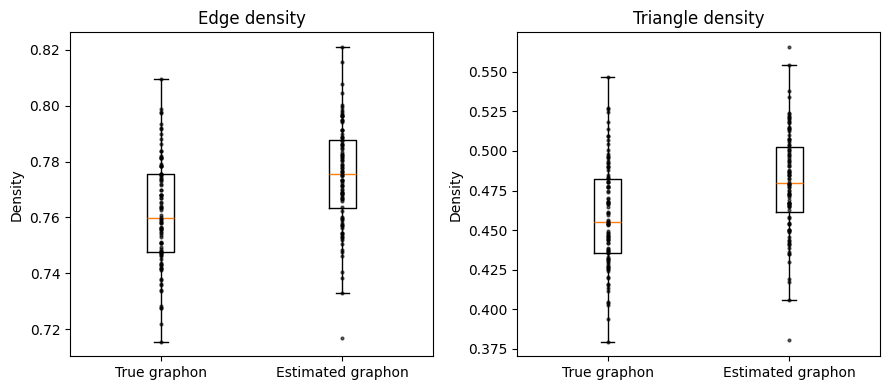

Edge density:     true mean=0.7615   estimated mean=0.7749
Triangle density: true mean=0.4593   estimated mean=0.4803


In [ ]:
from graphons import sample_graph_from_graphon, edge_density, triangle_density

n_graphs = 100
n_nodes = 100  # size of each sampled graph

edge_dens_true, edge_dens_est = [], []
tri_dens_true, tri_dens_est = [], []

for _ in range(n_graphs):
    A_true = sample_graph_from_graphon(graphon0, n_nodes)
    A_est = sample_graph_from_graphon(W1, n_nodes)

    edge_dens_true.append(edge_density(A_true))
    edge_dens_est.append(edge_density(A_est))
    tri_dens_true.append(triangle_density(A_true))
    tri_dens_est.append(triangle_density(A_est))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, (true_vals, est_vals), title in zip(
    axes,
    [(edge_dens_true, edge_dens_est), (tri_dens_true, tri_dens_est)],
    ["Edge density", "Triangle density"],
):
    ax.boxplot([true_vals, est_vals], labels=["True graphon", "Estimated graphon"], showfliers=False)

    ax.scatter(np.full(len(true_vals), 1), true_vals, color="black", alpha=0.6, s=4, zorder=3)
    ax.scatter(np.full(len(est_vals), 2), est_vals, color="black", alpha=0.6, s=4, zorder=3)

    ax.set_title(title)
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

print(f"Edge density:     true mean={np.mean(edge_dens_true):.4f}   estimated mean={np.mean(edge_dens_est):.4f}")
print(f"Triangle density: true mean={np.mean(tri_dens_true):.4f}   estimated mean={np.mean(tri_dens_est):.4f}")


The edge and triangle density distributions show that the estimated graphon reasonably approximates the true graphon's structure.